# La familia nula: ¿mantiene cada prueba su tamaño?

**Pregunta:** ¿Qué pruebas de validación rechazan un modelo correcto con más frecuencia de la que su nivel permite, y qué en la construcción de cada infractora lo explica?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (tamaño, potencia y error de Monte Carlo)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- aplicar la regla que decide si una prueba mantiene su tamaño, la probabilidad exacta donde existe y la cota unilateral sobre la tasa simulada donde no, a cada fila de la familia nula;
- nombrar las pruebas que rechazan un modelo correcto con más frecuencia de la que su nivel permite y decir, para cada una, qué parte de su construcción es responsable;
- reproducir con el motor el efecto de los grados de libertad de Hosmer-Lemeshow y la cola pesada de la prueba normal a cinco años, sobre los generadores del estudio;
- leer el tamaño exacto de la prueba de semáforos con sus dos reglas de empate y el de la prueba de Jeffreys en un rango de PD;
- tratar el AUC como un estimador y leer su sesgo, su error del modelo y la cobertura de su intervalo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son la familia `null` del caso C22, validar al validador: el mismo archivo del cuaderno 01, leído ahora completo. Cada fila corre una prueba registrada sobre conjuntos que sortea un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`) en el que la hipótesis nula se cumple, así que todo rechazo es una falsa alarma. La familia cubre las pruebas de las familias de crédito y las que el motor sumó después para exposición, provisiones, riesgo de mercado, crédito de cartera, equidad y aprendizaje automático.

- **Archivo que se lee:** `data/derived/C22/null.json`, claves `outputs` (filas, generadores, niveles) y `provenance`.
- **Qué se toma de él:** los conteos de cada fila, para aplicar la regla de tamaño, y la configuración y la semilla de algunas filas, para volver a sortear sus conjuntos aquí.

La celda siguiente carga el archivo, cuenta las filas nulas e imprime la versión del motor que lo escribió junto a la instalada.

In [2]:
# Cargar la familia nula e indexar sus simulaciones por clave
LANG = "es"
ROOT = Path("../../..").resolve()
null = json.loads((ROOT / "data" / "derived" / "C22" / "null.json").read_text(encoding="utf-8"))
out = null["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
null_keys = [key for key in rows if key.endswith("@null")]
print("simulaciones:", len(rows), "| filas nulas:", len(null_keys))
print("calculado con riskvalidation", null["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)

simulaciones: 53 | filas nulas: 46
calculado con riskvalidation 1.0.1 | instalado 1.0.1


## Método

El tamaño de una prueba es su probabilidad de rechazo cuando se cumple la nula, y el estudio lo estima como una tasa sobre 4000 repeticiones (cuaderno 01). Dos reglas convierten una tasa en un veredicto, aplicadas al 5 % y al 1 %:

- donde existe la probabilidad de rechazo exacta, como en las pruebas de conteo y en los semáforos sobre años independientes, la prueba mantiene su tamaño cuando $P(\text{rechazo}) \le \alpha$;
- donde no existe, la prueba mantiene su tamaño cuando la tasa simulada no supera $\alpha + 3{,}09\sqrt{\alpha(1-\alpha)/n}$, la cota que aplica el `within_size` del motor.

Una prueba que mantiene su tamaño en ambos niveles pasa. Los pasos aplican la regla a cada fila nula y luego abren las infractoras una por una: para cada una, un cálculo breve con el motor que reproduce su tamaño a partir de la forma en que la prueba está construida.

### Paso 1: la regla de tamaño sobre cada fila nula

Para cada fila que termina en `@null`, la celda siguiente toma la probabilidad exacta cuando la fila la tiene y, si no, construye un `Rate` con los conteos de la fila y pregunta a `within_size`. Escribe cuántas filas cumplen en ambos niveles y las tasas de las que no, y luego dibuja la tasa al 5 % de cada fila con su intervalo de Wilson, verde si la fila mantiene su tamaño y roja si no.

pruebas que mantienen su tamaño al 5 % y al 1 %: 42 de 46
pd.jeffreys@null                             [0.039, 0.0112]
pd.normal_multiperiod@null                   [0.0838, 0.0405]
market.christoffersen_independence@null      [0.0568, 0.0152]
market.christoffersen_conditional_coverage@null [0.069, 0.0143]


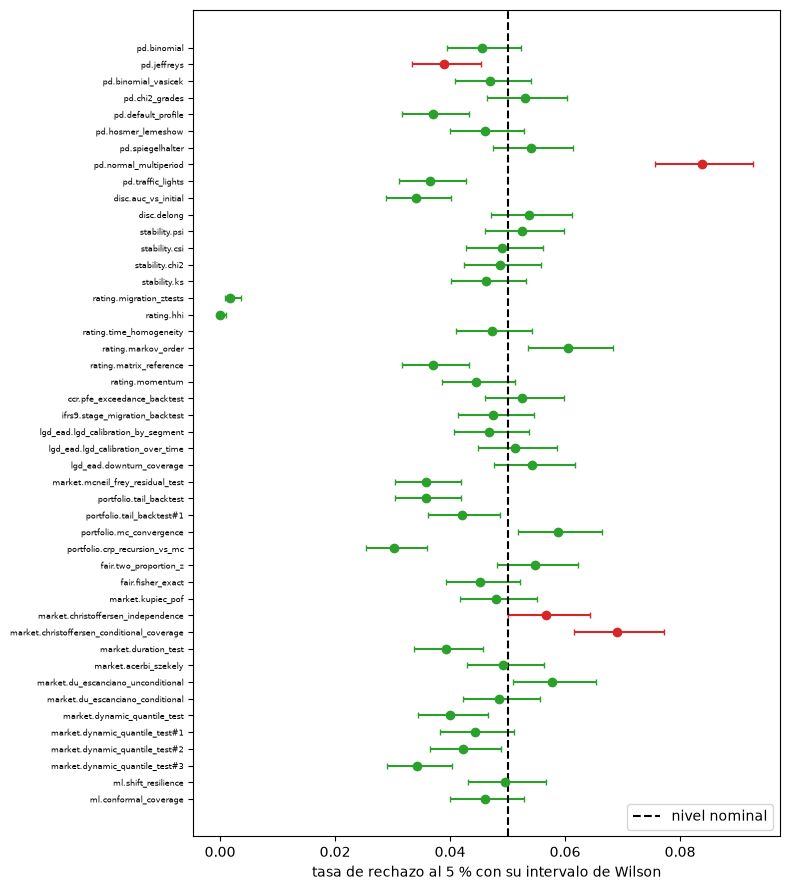

In [3]:
# Aplicar la regla de tamaño del motor a cada fila nula y dibujar las tasas con sus intervalos de Wilson
from riskvalidation.harness.rates import Rate, within_size

holds = {}
for key in null_keys:
    verdicts = []
    for alpha in out["levels"]:
        rule = f"p<{alpha:g}"
        exact = (rows[key]["exact"] or {}).get(rule)
        c = rows[key]["rates"][rule]
        rate = Rate(c["rejections"], c["n"])
        verdicts.append(exact <= alpha + 1e-12 if exact is not None else within_size(rate, alpha))
    holds[key] = all(verdicts)
print("pruebas que mantienen su tamaño al 5 % y al 1 %:", sum(holds.values()), "de", len(holds))
for key in null_keys:
    if not holds[key]:
        print(f"{key:44s}", [round(rows[key]["rates"][f"p<{a:g}"]["rate"], 4) for a in out["levels"]])
fig, ax = plt.subplots(figsize=(8, 9))
for i, key in enumerate(null_keys):
    c = rows[key]["rates"]["p<0.05"]
    errors = [[c["rate"] - c["wilson_low"]], [c["wilson_high"] - c["rate"]]]
    ax.errorbar(c["rate"], i, xerr=errors, fmt="o", capsize=2, color="tab:green" if holds[key] else "tab:red")
ax.axvline(0.05, color="black", linestyle="--", label="nivel nominal")
ax.set_yticks(range(len(null_keys)))
ax.set_yticklabels([key[:-5] for key in null_keys], fontsize=6)
ax.invert_yaxis()
ax.set_xlabel("tasa de rechazo al 5 % con su intervalo de Wilson")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

Cuarenta y dos de las 46 filas nulas mantienen su tamaño en ambos niveles. Las cuatro filas rojas son la prueba de Jeffreys, la prueba normal a cinco años y dos pruebas de Christoffersen sobre excedencias del valor en riesgo. La prueba normal es el caso nítido, con tasas de 0,0838 al 5 % y 0,0405 al 1 %, cerca del doble del nivel. Las otras tres quedan cerca de la línea: sus tasas, 0,0112, 0,0152 y 0,0690, superan la cota permitida en un solo nivel y por poco. Cada infractora se abre en los pasos siguientes.

### Paso 2: Hosmer-Lemeshow y sus grados de libertad

El estadístico de Hosmer-Lemeshow agrupa a los deudores en $G$ grupos por PD predicha y suma las brechas estandarizadas entre incumplimientos observados y esperados (Hosmer y Lemeshow, 1980). Cuando las PD vienen de un modelo ajustado sobre los mismos datos, la distribución de referencia original es $\chi^2_{G-2}$; cuando las PD son dadas, como en una validación, la brecha de cada grupo es asintóticamente normal y la referencia es $\chi^2_{G}$. El `pd_hosmer_lemeshow` del motor recibe una bandera `fitted`. La celda siguiente corre la prueba con `simulate` sobre el generador logístico del estudio, un modelo correcto de 5.000 deudores, una vez con cada referencia, y dibuja los valores p: bajo una prueba exacta son planos.

G grados de libertad     | 5%: 0.0475 | 1%: 0.0125
G-2 grados de libertad   | 5%: 0.1150 | 1%: 0.0300


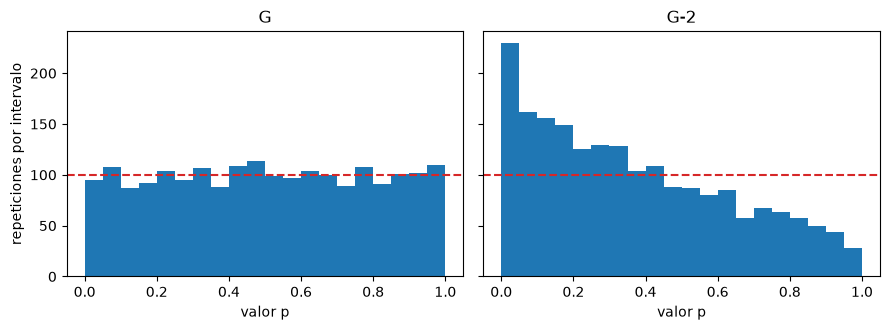

In [4]:
# Correr la prueba de Hosmer-Lemeshow con G y con G-2 grados de libertad sobre un modelo logístico correcto
from riskvalidation.generators.scores import LogisticPortfolio
from riskvalidation.harness.run import simulate

spec = out["generators"]["logistic-5000"]
logit = LogisticPortfolio(**spec["config"])
seed = rows["pd.hosmer_lemeshow@null"]["seed"]
given = simulate("pd.hosmer_lemeshow", logit, n_rep=2000, seed=seed)
fitted = simulate("pd.hosmer_lemeshow", logit, n_rep=2000, seed=seed, test_kwargs={"fitted": True})
for name, run in (("G grados de libertad", given), ("G-2 grados de libertad", fitted)):
    print(f"{name:24s} | 5%: {run.rates['p<0.05'].rate:.4f} | 1%: {run.rates['p<0.01'].rate:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, run, title in zip(axes, (given, fitted), ("G", "G-2")):
    ax.hist(run.p_values, bins=20, range=(0, 1), color="tab:blue")
    ax.axhline(len(run.p_values) / 20, color="tab:red", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("valor p")
axes[0].set_ylabel("repeticiones por intervalo")
fig.tight_layout()
plt.show()

Con la referencia que el estudio usa para PD dadas, las tasas son 0,0475 al 5 % y 0,0125 al 1 %, y el histograma de valores p es plano, como debe ser para un modelo correcto. Con $G-2$ grados de libertad el mismo estadístico rechaza el 0,1150 de las veces al 5 % y el 0,0300 al 1 %, y el histograma se apila en los primeros intervalos. Nada cambió en los datos: solo el umbral, y un umbral más bajo sobre el mismo estadístico es una tasa de falsas alarmas más alta. Usar la referencia del modelo ajustado para PD dadas es, por tanto, un defecto de la configuración y no de la prueba.

### Paso 3: la prueba normal a cinco años

La prueba normal multiperíodo del documento de trabajo 14 de BCBS suma las diferencias anuales entre la tasa de incumplimiento observada y la PD, y divide por una estimación de su dispersión. Con solo cinco años la dispersión se estima ella misma con cinco números, así que el cociente sigue una distribución t con cuatro grados de libertad y no una normal. Si esa es la causa, el tamaño debería igualar la cola de $t_4$ más allá del valor crítico normal. La celda siguiente corre la prueba sobre el generador de cinco años del estudio, con su semilla, escribe el tamaño simulado junto a esa cola y dibuja los valores p.

nivel 0.05 | tamaño simulado 0.0838 | cola de t con 4 grados de libertad 0.0877
nivel 0.01 | tamaño simulado 0.0405 | cola de t con 4 grados de libertad 0.0403


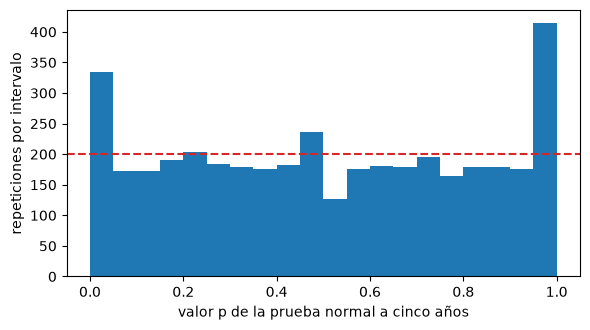

In [5]:
# Comparar el tamaño simulado de la prueba normal a cinco años con la cola de una distribución t
from riskvalidation.generators.counts import DefaultCounts, feed_series

row = rows["pd.normal_multiperiod@null"]
generator = DefaultCounts(**out["generators"][row["generator"]]["config"])
run = simulate(row["test_id"], generator, n_rep=row["n_rep"], seed=row["seed"], feed=feed_series())
for alpha in (0.05, 0.01):
    measured = run.rates[f"p<{alpha:g}"]
    t_tail = stats.t.sf(stats.norm.isf(alpha), 4)
    print(f"nivel {alpha:.2f} | tamaño simulado {measured.rate:.4f} | cola de t con 4 grados de libertad {t_tail:.4f}")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(run.p_values, bins=20, range=(0, 1), color="tab:blue")
ax.axhline(len(run.p_values) / 20, color="tab:red", linestyle="--")
ax.set_xlabel("valor p de la prueba normal a cinco años")
ax.set_ylabel("repeticiones por intervalo")
fig.tight_layout()
plt.show()

El tamaño simulado es 0,0838 al 5 % contra una cola t de 0,0877, y 0,0405 al 1 % contra 0,0403: la cola pesada de cuatro grados de libertad explica el exceso. El histograma de valores p no tiene un piso plano sino un primer intervalo alto, la firma de un umbral demasiado optimista. El propio documento describe la prueba como conservadora; con años independientes y una PD aplicada exactamente correcta, este experimento muestra que es anticonservadora, y en un factor cercano a dos al 1 %.

### Paso 4: empates en los semáforos y la prueba de Jeffreys al 1 %

La prueba de semáforos colorea cada año según su tasa de incumplimiento estandarizada y rechaza cuando el perfil de colores es suficientemente malo. Un año con exactamente el número esperado de incumplimientos queda sobre una frontera de color, y el motor ofrece dos reglas para ello, `lower` y `upper`. La prueba de semáforos tiene una probabilidad de rechazo exacta, que `traffic_lights_rejection_probability` entrega para años independientes. Para las pruebas de conteo, `critical_count` y `rejection_probability` dan a la prueba de Jeffreys su tamaño al 1 %. La celda siguiente imprime ambas.

In [6]:
# Tamaño exacto de la prueba de semáforos con las dos reglas de empate, y de la prueba de Jeffreys al 1 %
from riskvalidation.harness.exact import critical_count, rejection_probability, traffic_lights_rejection_probability

for ties in ("lower", "upper"):
    for alpha in (0.05, 0.01):
        exact = traffic_lights_rejection_probability([1000] * 5, 0.03, alpha, pd_true=0.03, ties=ties)["probability"]
        print(f"semáforos, empates={ties:5s} | nivel {alpha:.2f} | tamaño exacto {exact:.4f}")
for test in ("pd.binomial", "pd.jeffreys"):
    k_star = critical_count(test, 1000, 0.01, 0.01)
    size = rejection_probability(test, 1000, 0.01, 0.01)["probability"]
    print(f"{test:12s} | 1% | conteo crítico {k_star} | tamaño exacto {size:.5f}")

semáforos, empates=lower | nivel 0.05 | tamaño exacto 0.0379
semáforos, empates=lower | nivel 0.01 | tamaño exacto 0.0074
semáforos, empates=upper | nivel 0.05 | tamaño exacto 0.0603
semáforos, empates=upper | nivel 0.01 | tamaño exacto 0.0113
pd.binomial  | 1% | conteo crítico 19 | tamaño exacto 0.00690
pd.jeffreys  | 1% | conteo crítico 18 | tamaño exacto 0.01383


La regla de empate mueve a la prueba de semáforos a ambos lados de su nivel nominal: con `lower` el tamaño exacto es 0,0379 al 5 % y 0,0074 al 1 %, bajo el nivel, y con `upper` es 0,0603 y 0,0113, sobre él. La prueba no es correcta ni incorrecta hasta que se declara la regla. La prueba de Jeffreys necesita 18 incumplimientos para rechazar al 1 % donde la binomial necesita 19, y su tamaño exacto es 0,01383 contra 0,00690 para la binomial: un incumplimiento más en la región de rechazo empuja a la de Jeffreys sobre su nivel.

### Paso 5: ¿es el exceso de Jeffreys una característica de una sola cartera?

El paso anterior usó una cartera de 1.000 deudores con una PD de 1 %. Una prueba discreta puede estar sobre su nivel con una PD y bajo él con la siguiente, así que el veredicto de un solo punto es débil. Como el tamaño exacto no necesita simulación, la celda siguiente lo calcula para ambas pruebas de conteo con PD de 0,2 % a 5 % sobre los mismos 1.000 deudores, escribe el mayor y el menor tamaño exacto y dibuja las dos curvas frente al 1 % nominal.

pd.binomial  | mayor tamaño exacto al 1 % 0.00974 | menor 0.00374
pd.jeffreys  | mayor tamaño exacto al 1 % 0.01646 | menor 0.00798


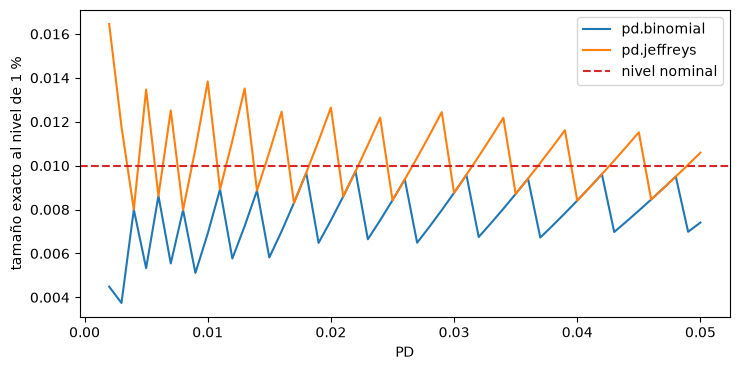

In [7]:
# Dibujar el tamaño exacto de ambas pruebas de conteo contra la PD de una cartera de 1000 deudores
pds = np.linspace(0.002, 0.05, 49)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for test, color in (("pd.binomial", "tab:blue"), ("pd.jeffreys", "tab:orange")):
    sizes = [rejection_probability(test, 1000, pd, 0.01)["probability"] for pd in pds]
    ax.plot(pds, sizes, color=color, label=test)
    print(f"{test:12s} | mayor tamaño exacto al 1 % {max(sizes):.5f} | menor {min(sizes):.5f}")
ax.axhline(0.01, color="tab:red", linestyle="--", label="nivel nominal")
ax.set_xlabel("PD")
ax.set_ylabel("tamaño exacto al nivel de 1 %")
ax.legend()
fig.tight_layout()
plt.show()

Ambas curvas hacen dientes de sierra porque el conteo crítico salta en defaults enteros. La prueba binomial nunca excede su nivel en este rango, con un tamaño exacto máximo de 0,00974, y baja hasta 0,00374. La prueba de Jeffreys llega a 0,01646 y cae a 0,00798, así que cruza la línea del 1 % nominal una y otra vez. El exceso del paso anterior no es entonces una cartera desafortunada sino el comportamiento de la prueba: rechaza un incumplimiento antes que la binomial, y al nivel de 1 % eso cuesta un tamaño sobre el nivel en parte del rango.

### Paso 6: una métrica descriptiva cuando el modelo es correcto

No toda salida del motor es una prueba. El AUC es una estimación, y un validador la lee con sus propias medidas de desempeño: sesgo, error estándar empírico, error estándar del modelo del motor y cobertura de su intervalo de 95 %. La celda siguiente sortea 400 conjuntos del generador binormal del estudio con 150 incumplidores, calcula `auc_with_variance` en cada uno, pasa las estimaciones y los errores del modelo a `estimator_performance` y dibuja las estimaciones alrededor del AUC verdadero.

AUC verdadero: 0.80193 | sorteos: 400
sesgo: -0.00038 | error empírico: 0.0188
error del modelo respecto del empírico, %: -4.57
cobertura del intervalo de 95 %: 0.935


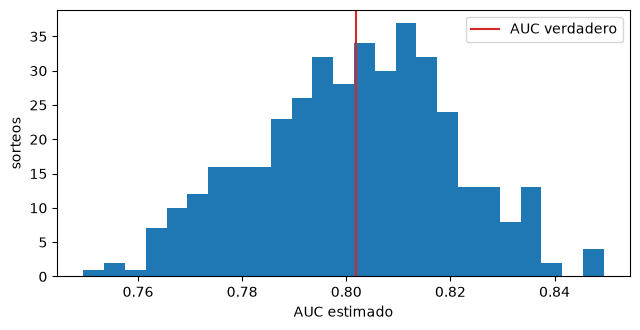

In [8]:
# Medir el AUC como estimador en 400 sorteos nuevos: sesgo, error del modelo y cobertura
from riskvalidation.generators.scores import BinormalScores
from riskvalidation.harness.performance import estimator_performance
from riskvalidation.validation.discrimination import auc_with_variance

binormal = BinormalScores(**out["generators"]["binormal-150"]["config"])
estimates, model_se = [], []
for child in np.random.SeedSequence(11).spawn(400):
    sample = binormal.draw(np.random.default_rng(child))
    auc_hat, variance, _, _ = auc_with_variance(sample["risk"], sample["defaults"])
    estimates.append(auc_hat)
    model_se.append(np.sqrt(variance))
estimates, model_se = np.array(estimates), np.array(model_se)
truth = binormal.truth()["auc_current"]
lower, upper = estimates - 1.96 * model_se, estimates + 1.96 * model_se
perf = estimator_performance(estimates, truth, model_se=model_se, lower=lower, upper=upper)
print("AUC verdadero:", round(truth, 5), "| sorteos:", perf["n"])
print("sesgo:", round(perf["bias"], 5), "| error empírico:", round(perf["empirical_se"], 5))
print("error del modelo respecto del empírico, %:", round(perf["model_se_relative_error_pct"], 2))
print("cobertura del intervalo de 95 %:", round(perf["coverage"], 4))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(estimates, bins=25, color="tab:blue")
ax.axvline(truth, color="tab:red", label="AUC verdadero")
ax.set_xlabel("AUC estimado")
ax.set_ylabel("sorteos")
ax.legend()
fig.tight_layout()
plt.show()

El AUC verdadero del generador es 0,80193 y las estimaciones se centran en él: el sesgo es -0,00038, muy por debajo del error empírico de 0,0188. El error del modelo queda 4,57 % bajo el empírico, así que el intervalo es algo estrecho, y la cobertura del intervalo nominal de 95 % es 0,935. Con 400 sorteos el error de Monte Carlo de una cobertura cercana a 0,95 es de alrededor de un punto, de modo que el déficit es leve pero visible. Un estimador puede ser insesgado y aun así informar un intervalo algo más estrecho de lo que merece.

## Resultados

**Respuesta:** Cuatro de las 46 filas nulas rechazan un modelo correcto más de lo que su nivel permite, de modo que 42 mantienen su tamaño en ambos niveles. La infractora más clara es la prueba normal a cinco años, con tamaños de 0,0838 al 5 % y 0,0405 al 1 %, que explica la cola de una distribución t con cuatro grados de libertad (0,0877 y 0,0403). Hosmer-Lemeshow con $G-2$ grados de libertad rechaza el 0,1150 de las veces al 5 % contra 0,0475 con la referencia para PD dadas, y la prueba de Jeffreys tiene un tamaño exacto de 0,01383 al 1 %.

- **La causa está en la construcción.** Una distribución de referencia que no corresponde a la configuración (Hosmer-Lemeshow), una dispersión estimada con cinco puntos (la prueba normal), un conteo crítico discreto (la prueba de Jeffreys) y una regla de empate (los semáforos, 0,0379 con `lower` y 0,0603 con `upper` al 5 %) explican cada una un tamaño, y cada una se reproduce en pocas líneas del motor.
- **Lo exacto supera a lo simulado.** Para las pruebas de conteo y los semáforos el tamaño exacto zanja el veredicto sin error de Monte Carlo; la prueba de Jeffreys va de 0,00798 a 0,01646 al 1 % según la PD, mientras la binomial se queda en 0,00974 o menos.
- **Los estimadores no son pruebas.** El AUC tiene un sesgo de -0,00038 pero su intervalo cubre 0,935 de las veces, no 0,95.

Lo que este cuaderno no hace es medir la potencia; eso es tarea del cuaderno 03.

## Resumen

- Una prueba mantiene su tamaño cuando su probabilidad de rechazo exacta, o su tasa simulada frente a la cota unilateral, es a lo más el nivel al 5 % y al 1 %.
- De las 46 filas nulas del estudio, 42 mantienen su tamaño; las infractoras son la prueba de Jeffreys, la prueba normal a cinco años y dos pruebas de Christoffersen.
- Cada infractora se remonta a su construcción: la distribución de referencia equivocada, una dispersión estimada con cinco puntos, un conteo crítico discreto o una regla de empate no declarada.
- El tamaño exacto de una prueba de conteo no necesita simulación y muestra los dientes de sierra que una sola cartera oculta.
- El AUC es un estimador y se lee con su sesgo, su error del modelo y la cobertura de su intervalo.

**Qué probar después.** Repite el paso 3 con diez años en vez de cinco y mira al tamaño acercarse al nivel nominal; luego lee el cuaderno 03.

## Referencias

- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): la prueba normal multiperíodo, la prueba de semáforo y la prueba chi-cuadrado por grados. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, secciones 2.5.3.1 a 2.5.5 y Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Este repositorio: `docs/design/features/c22-validator/requirements.md` y `data-pipeline/pipeline/cases/c22_validator.py`, que escribió el artefacto.